# Recognition on detected crops

Runs the baseline TrOCR checkpoint (same weights, beam 4, `max_length=130`) on RF-DETR Small crops of the validation pages and compares it with annotated crops on exactly the same ground-truth lines. Matched-line scores are conditional on detection; missed lines are reported separately.

In [1]:
import json
import sys
import time
from pathlib import Path

import jiwer
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from transformers import TrOCRProcessor, VisionEncoderDecoderModel
from transformers.utils import logging

sys.path.insert(0, '../src')
from htr import ROOT, cer, predict, wer

logging.set_verbosity_error()
logging.disable_progress_bar()
pd.set_option('display.max_colwidth', 100)

MODEL_DIR = Path('../models/trocr-uk-baseline')
RESULTS_DIR = Path('../results/htr')
DECODING = dict(num_beams=4, no_repeat_ngram_size=0, max_length=130)
DETECTOR = 'rf-small-refined'

/home/stalex/unik_shit/ai/pandemonium-rukopys/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
crop_dir = (ROOT / 'data/detector_crops' / DETECTOR).resolve()
pred = pd.read_csv(crop_dir / 'crops.csv')
pred['crop_path'] = [str(crop_dir / p.split('/')[-1]) for p in pred['crop_path']]
pred['gt_region'] = pred['gt_region'].astype('Int64')
coverage = json.loads((crop_dir / 'coverage.json').read_text())

ann = pd.read_csv(RESULTS_DIR / 'val_predictions.csv')
matched = pred[pred.target.notna()].copy()
assert len(ann) == coverage['eligible_gt_lines'] and len(matched) == coverage['matched_lines']

processor = TrOCRProcessor.from_pretrained(MODEL_DIR)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_DIR).cuda()
start = time.time()
matched['prediction'] = predict(model, processor, matched, **DECODING)
print(f'{len(matched)} detected crops, {1000 * (time.time() - start) / len(matched):.0f} ms per line')

1862 detected crops, 178 ms per line


In [3]:
measures = [jiwer.process_characters(r, h) for r, h in zip(matched.target, matched.prediction)]
matched['char_errors'] = [m.substitutions + m.deletions + m.insertions for m in measures]
matched['chars'] = matched.target.str.len()
matched['line_CER'] = matched.char_errors / matched.chars

# join on the GT line each detection was matched to (`region` of a prediction is not a GT id)
ann_cols = ann.rename(columns={'region': 'gt_region', 'prediction': 'ann_prediction', 'char_errors': 'ann_errors',
                               'crop_path': 'ann_crop', 'target': 'ann_target'})
both = matched.merge(ann_cols[['page_id', 'gt_region', 'ann_prediction', 'ann_errors', 'ann_crop', 'ann_target']],
                     on=['page_id', 'gt_region'])
assert len(both) == len(matched) and (both.target == both.ann_target).all()


def score(df, name, hyp):
    return dict(crops=name, lines=len(df), CER=cer(df.target, df[hyp]), WER=wer(df.target, df[hyp]))


rows = [dict(source='all eligible', **score(ann, 'annotated', 'prediction'))]
for source, g in [('all matched', both)] + list(both.groupby('source')):
    rows += [dict(source=source, **score(g, 'annotated', 'ann_prediction')),
             dict(source=source, **score(g, 'detected', 'prediction'))]
table = pd.DataFrame(rows).round(4)
table

,source,crops,lines,CER,WER
0,all eligible,annotated,2076,0.1145,0.3150
1,all matched,annotated,1862,0.1102,0.3071
2,all matched,detected,1862,0.1119,0.3056
3,archive,annotated,289,0.1176,0.3581
4,archive,detected,289,0.1159,0.3554
5,dictation,annotated,742,0.0710,0.1665
6,dictation,detected,742,0.0720,0.1677
7,school,annotated,583,0.1129,0.3641
8,school,detected,583,0.1145,0.3570
9,university,annotated,248,0.1958,0.5503


Coverage on validation (score ≥ 0.55). Matched-line CER excludes the missed lines, so it is not page CER.

In [4]:
pd.Series({k: v for k, v in coverage.items() if k != 'note'})

eligible_gt_lines        2076.000000
matched_lines            1862.000000
predicted_lines          2063.000000
missed_lines              214.000000
unmatched_predictions     201.000000
matched_coverage            0.896917
score_threshold             0.550000
dtype: float64

## Examples

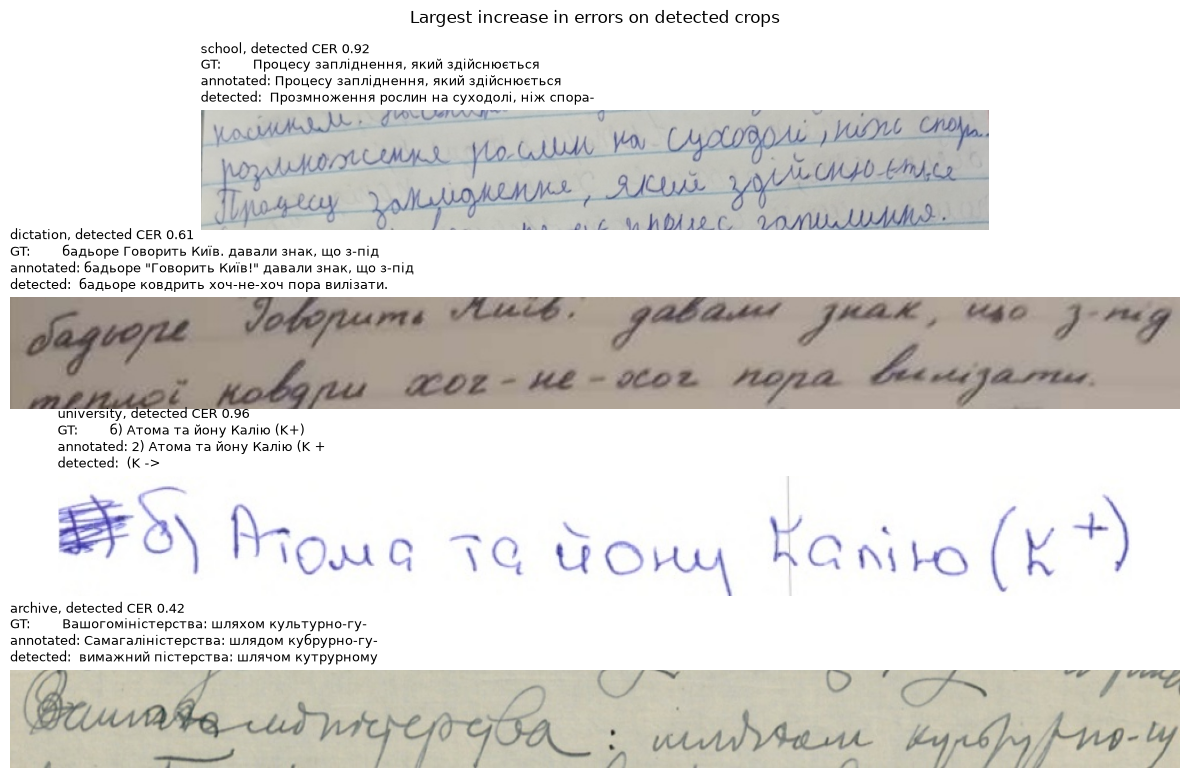

In [5]:
def show(df, title, path):
    fig, axes = plt.subplots(len(df), 1, figsize=(12, 2.0 * len(df)))
    for ax, row in zip(axes, df.itertuples()):
        with Image.open(row.crop_path) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f'{row.source}, detected CER {row.line_CER:.2f}\nGT:        {row.target}\n'
                     f'annotated: {row.ann_prediction}\ndetected:  {row.prediction}', loc='left', fontsize=9)
        ax.axis('off')
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, dpi=120)


long = both[both.chars >= 15].copy()
long['delta'] = long.char_errors - long.ann_errors
show(long.sort_values('delta', ascending=False).groupby('source').head(1),
     'Largest increase in errors on detected crops', RESULTS_DIR / 'detected_hurt.png')

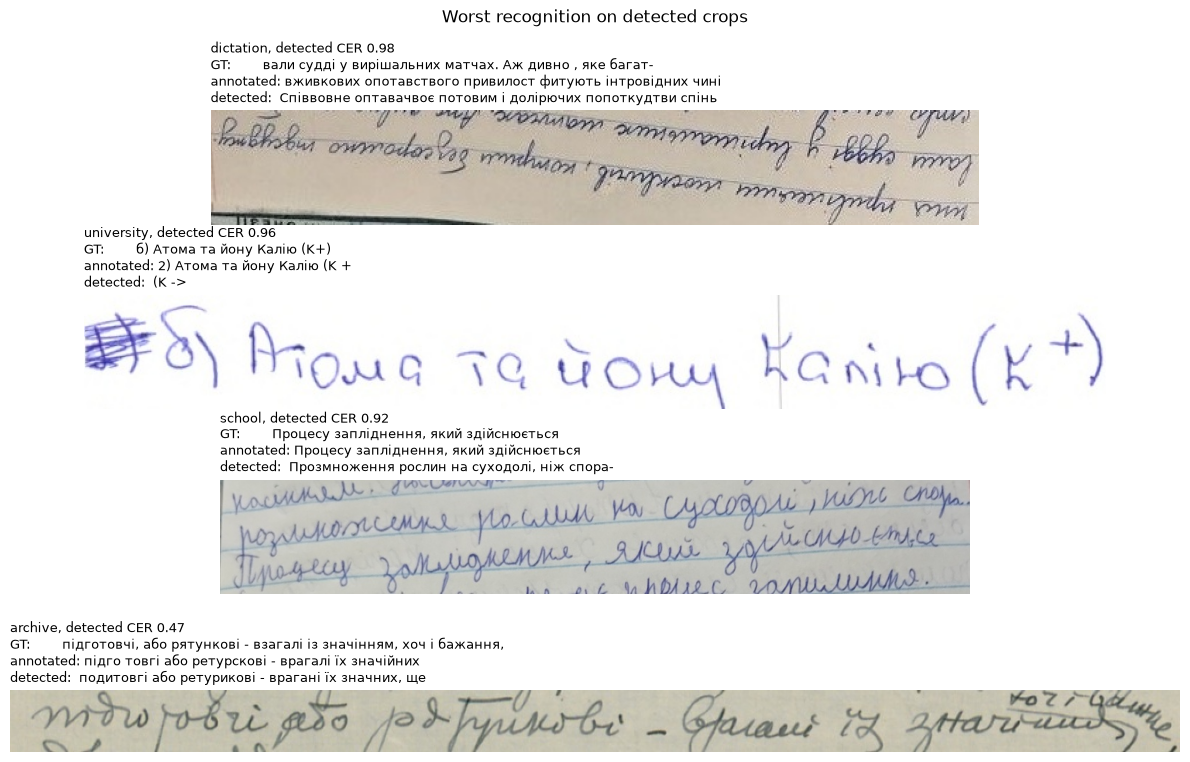

In [6]:
show(long.sort_values('line_CER', ascending=False).groupby('source').head(1),
     'Worst recognition on detected crops', RESULTS_DIR / 'detected_failures.png')

Eligible lines the detector missed (no prediction with IoU ≥ 0.5 at the 0.55 threshold):

In [7]:
found = set(zip(both.page_id, both.gt_region))
missed = ann[[(p, r) not in found for p, r in zip(ann.page_id, ann.region)]]
print(len(missed), 'missed;', missed.groupby('source').size().to_dict())
missed.sample(8, random_state=42)[['source', 'target']]

214 missed; {'archive': 16, 'dictation': 60, 'school': 108, 'university': 30}


,source,target
105,dictation,"співачки Оксани Петрусенко, чий спів у"
1918,school,↑1↓s ↑2↓s ↑↑↑2p
966,archive,ця потреба є далеко всих
1905,school,1s^2 2s^2 2p^3 - Ел. форм.
1459,school,я будь-який скільки
1437,school,2. - г. 4. - а. 6. - б.
162,dictation,"Київ,"" давали знак, що з-під теплої"
1185,university,кої діяльності з метою виробництва товарів або надання


## Save

In [8]:
(RESULTS_DIR / f'detected_{DETECTOR}_metrics.json').write_text(json.dumps(dict(
    detector=DETECTOR, model=str(MODEL_DIR), decoding=DECODING, coverage=coverage,
    results=table.to_dict('records')), indent=2), encoding='utf-8')
both['crop_path'] = both.crop_path.map(lambda p: Path(p).name)
both[['page_id', 'region', 'gt_region', 'crop_path', 'source', 'score', 'iou', 'target', 'prediction',
      'char_errors', 'chars', 'ann_prediction', 'ann_errors']].to_csv(
    RESULTS_DIR / f'detected_{DETECTOR}_predictions.csv', index=False)